# IntelliSense Backtest Analysis
Compare the performance of **Fixed Q-table**, **Q-learning**, and **DQN** strategies across different tickers.

---

In [6]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks" and (Path.cwd().parent / "run.py").exists():
    os.chdir(Path.cwd().parent)

import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
import json
import os
import numpy as np
from IPython.display import display, Markdown, HTML

def compute_metrics(trades_df, stock_df):
    """Compute Max DD, Alpha (vs S&P 500), Sharpe Ratio, and Win Rate."""
    
    portfolio_values = trades_df['portfolio_value'].values
    
    # --- Max Drawdown ---
    running_max = np.maximum.accumulate(portfolio_values)
    drawdowns = (running_max - portfolio_values) / running_max
    max_dd = np.max(drawdowns) * 100
    
    # --- Total Return ---
    initial_val = portfolio_values[0]
    final_val = portfolio_values[-1]
    total_return = (final_val - initial_val) / initial_val
    
    # --- Alpha (vs S&P 500 benchmark) ---
    dates = pd.to_datetime(trades_df['date'])
    n_years = (dates.iloc[-1] - dates.iloc[0]).days / 365.25
    sp500_annual_return = 0.10
    sp500_period_return = (1 + sp500_annual_return) ** n_years - 1
    alpha = (total_return - sp500_period_return) * 100
    
    # --- Sharpe Ratio (annualized, weekly data, 0% risk-free) ---
    weekly_returns = np.diff(portfolio_values) / portfolio_values[:-1]
    if np.std(weekly_returns) > 0:
        sharpe = (np.mean(weekly_returns) / np.std(weekly_returns)) * np.sqrt(52)
    else:
        sharpe = 0.0
    
    # --- Win Rate (only count trades where shares > 0) ---
    real_buys = trades_df[(trades_df['action'] == 'BUY') & (trades_df['shares'] > 0)]
    real_sells = trades_df[(trades_df['action'] == 'SELL') & (trades_df['shares'] > 0)]
    
    wins = 0
    total_trades = 0
    buy_prices = []
    avg_entry = None
    prev_action = None
    
    for _, row in trades_df.iterrows():
        if row['action'] == 'BUY' and row['shares'] > 0:
            if prev_action != 'BUY':
                buy_prices = []
            buy_prices.append(row['price'])
            avg_entry = np.mean(buy_prices)
            prev_action = 'BUY'
        elif row['action'] == 'SELL' and row['shares'] > 0 and avg_entry is not None:
            if row['price'] > avg_entry:
                wins += 1
            total_trades += 1
            prev_action = 'SELL'
    
    win_rate = (wins / total_trades * 100) if total_trades > 0 else 0.0
    
    return {
        'max_dd': max_dd,
        'alpha': alpha,
        'sharpe': sharpe,
        'win_rate': win_rate,
        'total_return': total_return * 100,
        'final_val': final_val,
        'n_buys': len(real_buys),
        'n_sells': len(real_sells),
        'total_trades': total_trades,
        'wins': wins
    }


def build_trade_log(trades_df):
    """Build a styled trade log table showing only executed BUY/SELL (shares > 0)."""
    # Filter to only executed trades (shares > 0)
    active = trades_df[
        (trades_df['action'].isin(['BUY', 'SELL'])) & (trades_df['shares'] > 0)
    ].copy()
    active = active.reset_index(drop=True)
    
    # Format columns
    log = pd.DataFrame()
    log['Date'] = pd.to_datetime(active['date']).dt.strftime('%Y-%m-%d')
    log['Action'] = active['action']
    log['Price'] = active['price'].map('${:,.2f}'.format)
    log['Shares'] = active['shares'].map('{:,.0f}'.format)
    log['Value'] = active['value'].map('${:,.2f}'.format)
    log['Portfolio'] = active['portfolio_value'].map('${:,.2f}'.format)
    
    return log


def style_trade_log(log):
    """Apply color styling to the trade log."""
    def color_action(val):
        if val == 'BUY':
            return 'color: #00c853; font-weight: bold'
        elif val == 'SELL':
            return 'color: #ff1744; font-weight: bold'
        return ''
    
    styled = log.style.applymap(
        color_action, subset=['Action']
    ).set_properties(**{
        'text-align': 'right',
        'font-size': '12px',
        'padding': '4px 8px',
    }).set_table_styles([
        {'selector': 'th', 'props': [
            ('background-color', '#2d2d44'),
            ('color', 'white'),
            ('font-size', '13px'),
            ('text-align', 'center'),
            ('padding', '6px 10px'),
        ]},
        {'selector': 'td', 'props': [
            ('border-bottom', '1px solid #444'),
        ]},
    ]).hide(axis='index')
    
    return styled


def plot_ticker(ticker, method='DQN_Price_Only'):
    """Plot candlestick chart with buy/sell arrows and trade log."""
    results_dir = 'test_results'
    data_dir = 'data'
    
    # --- Load trade history ---
    history_file = os.path.join(results_dir, f'{ticker}_{method}_history.json')
    if not os.path.exists(history_file):
        print(f'No trade history found for {ticker} ({method}) at {history_file}')
        return
    
    with open(history_file, 'r') as f:
        trades = json.load(f)
    trades_df = pd.DataFrame(trades)
    trades_df['date'] = pd.to_datetime(trades_df['date'])
    
    # --- Load weekly stock data ---
    stock_file = os.path.join(data_dir, f'{ticker}_weekly_stock_data.csv')
    if not os.path.exists(stock_file):
        print(f'No stock data found for {ticker} at {stock_file}')
        return
    
    stock_df = pd.read_csv(stock_file, index_col=0, parse_dates=True)
    stock_df.columns = [c.strip().title() for c in stock_df.columns]
    stock_df = stock_df.sort_index()
    
    # --- Adjust OHLC prices for stock splits/dividends ---
    if 'Adjusted_Close' in stock_df.columns and 'Close' in stock_df.columns:
        adj_factor = stock_df['Adjusted_Close'] / stock_df['Close']
        adj_factor = adj_factor.replace([np.inf, -np.inf], np.nan).fillna(1.0)
        for col in ['Open', 'High', 'Low', 'Close']:
            stock_df[col] = stock_df[col] * adj_factor
    
    # Filter stock data to backtest period
    start_date = trades_df['date'].min()
    end_date = trades_df['date'].max()
    stock_df = stock_df[(stock_df.index >= start_date) & (stock_df.index <= end_date + pd.Timedelta(days=7))]
    
    if stock_df.empty:
        print(f'No stock data in the backtest date range for {ticker}')
        return
    
    # --- Compute performance metrics ---
    metrics = compute_metrics(trades_df, stock_df)
    
    # --- Extract only EXECUTED BUY and SELL trades (shares > 0) ---
    buys = trades_df[(trades_df['action'] == 'BUY') & (trades_df['shares'] > 0)].copy()
    sells = trades_df[(trades_df['action'] == 'SELL') & (trades_df['shares'] > 0)].copy()
    
    buy_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    sell_markers = pd.Series(np.nan, index=stock_df.index, dtype=float)
    
    for _, trade in buys.iterrows():
        trade_date = trade['date']
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            buy_markers[nearest_date] = stock_df.loc[nearest_date, 'Low'] * 0.97
    
    for _, trade in sells.iterrows():
        trade_date = trade['date']
        nearest_idx = stock_df.index.get_indexer([trade_date], method='nearest')[0]
        if nearest_idx >= 0 and nearest_idx < len(stock_df):
            nearest_date = stock_df.index[nearest_idx]
            sell_markers[nearest_date] = stock_df.loc[nearest_date, 'High'] * 1.03
    
    # --- Build mplfinance addplots ---
    addplots = []
    if buy_markers.notna().any():
        addplots.append(mpf.make_addplot(
            buy_markers, type='scatter', marker='^', markersize=100,
            color='#00c853', secondary_y=False
        ))
    if sell_markers.notna().any():
        addplots.append(mpf.make_addplot(
            sell_markers, type='scatter', marker='v', markersize=100,
            color='#ff1744', secondary_y=False
        ))
    
    # --- Custom style ---
    custom_style = mpf.make_mpf_style(
        base_mpf_style='nightclouds',
        marketcolors=mpf.make_marketcolors(
            up='#00c853', down='#ff1744',
            edge={'up': '#00c853', 'down': '#ff1744'},
            wick={'up': '#00c853', 'down': '#ff1744'},
            volume='in'
        ),
        facecolor='#1a1a2e',
        edgecolor='#1a1a2e',
        figcolor='#1a1a2e',
        gridcolor='#2d2d44',
        gridstyle='--',
        gridaxis='both',
        y_on_right=True,
        rc={'font.size': 10}
    )
    
    # --- Title with core stats ---
    title = (f'{ticker} — {method.replace("_", " ")} Strategy\n'
             f'Return: {metrics["total_return"]:+.1f}%  |  '
             f'Final: ${metrics["final_val"]:,.0f}  |  '
             f'Buys: {metrics["n_buys"]}  |  Sells: {metrics["n_sells"]}')
    
    # --- Plot ---
    fig, axes = mpf.plot(
        stock_df, type='candle', style=custom_style,
        volume=True, addplot=addplots if addplots else None,
        title=title, figsize=(18, 10),
        tight_layout=False, returnfig=True,
        panel_ratios=(4, 1),
        warn_too_much_data=9999
    )
    
    # Add legend
    ax_main = axes[0]
    ax_main.scatter([], [], marker='^', s=100, color='#00c853', label='BUY')
    ax_main.scatter([], [], marker='v', s=100, color='#ff1744', label='SELL')
    ax_main.legend(loc='upper left', fontsize=12, framealpha=0.7,
                  facecolor='#1a1a2e', edgecolor='#444',
                  labelcolor='white')
    
    # --- Metrics box below the chart ---
    metrics_text = (
        f'Max DD: {metrics["max_dd"]:.1f}%    '
        f'Alpha (vs S&P): {metrics["alpha"]:+.1f}%    '
        f'Sharpe: {metrics["sharpe"]:.2f}    '
        f'Win Rate: {metrics["win_rate"]:.0f}% '
        f'({metrics["wins"]}/{metrics["total_trades"]} trades)'
    )
    
    fig.text(
        0.5, 0.01, metrics_text,
        ha='center', va='bottom', fontsize=13,
        color='white', fontweight='bold',
        fontstyle='italic',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#2d2d44',
                  edgecolor='#555', alpha=0.9)
    )
    
    fig.subplots_adjust(bottom=0.08)
    plt.show()
    
    # --- Trade Log Table ---
    display(Markdown(f'### {ticker} — Trade Log ({method.replace("_", " ")})'))
    log = build_trade_log(trades_df)
    display(style_trade_log(log))


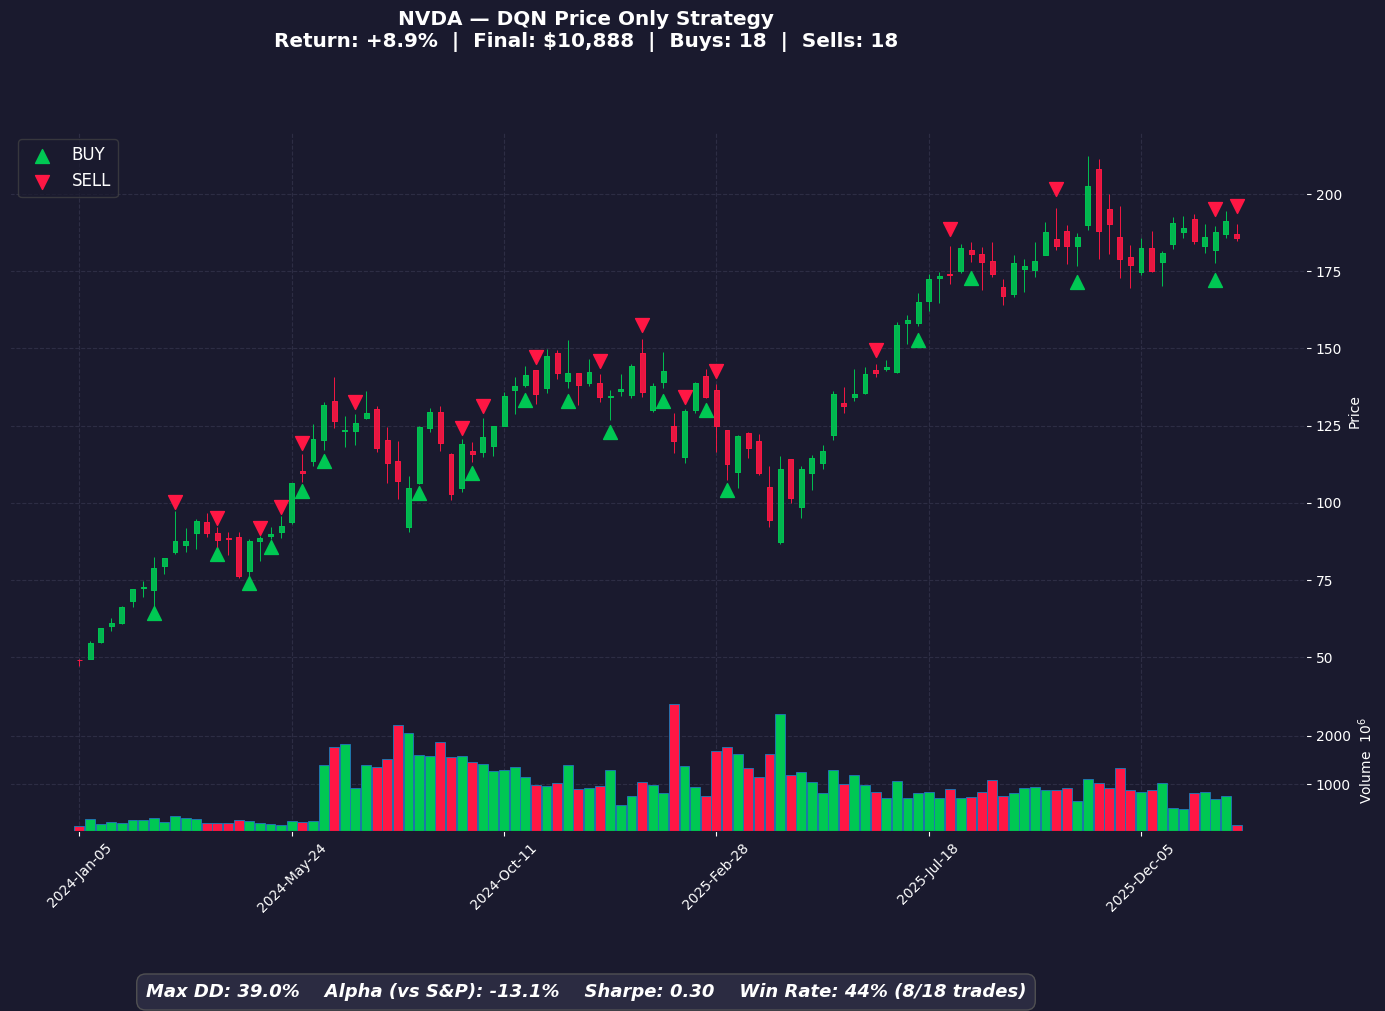

### NVDA — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_38119/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-26,BUY,$79.05,126,"$9,960.12","$9,990.04"
2024-03-11,SELL,$85.73,126,"$10,802.09","$10,821.21"
2024-04-01,BUY,$90.32,119,"$10,747.79","$10,810.46"
2024-04-08,SELL,$87.09,119,"$10,363.61","$10,415.92"
2024-04-29,BUY,$87.71,118,"$10,350.12","$10,405.57"
2024-05-06,SELL,$92.09,118,"$10,867.05","$10,911.64"
2024-05-13,BUY,$90.35,120,"$10,842.43","$10,900.80"
2024-05-20,SELL,$94.73,120,"$11,367.88","$11,414.88"
2024-05-28,BUY,$113.84,100,"$11,384.37","$11,403.50"
2024-06-03,SELL,$114.94,100,"$11,494.22","$11,501.85"


In [7]:
plot_ticker('NVDA', method='DQN_Price_Only')


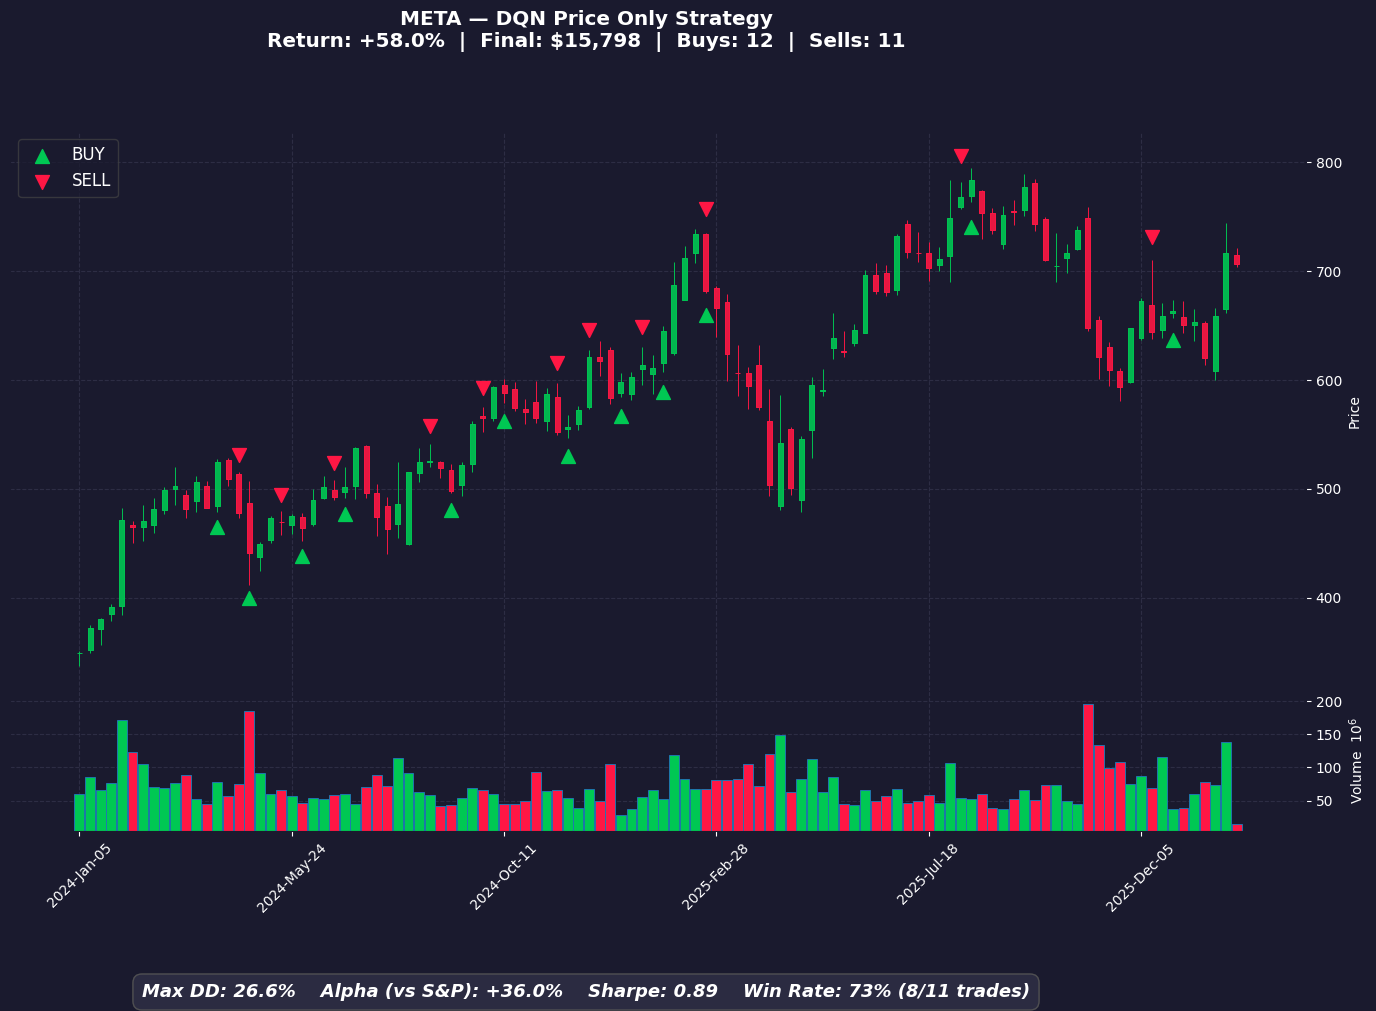

### META — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_38119/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-04-01,BUY,$488.49,20,"$9,769.81","$9,990.23"
2024-04-22,SELL,$478.93,20,"$9,578.53","$9,789.37"
2024-04-29,BUY,$430.10,22,"$9,462.25","$9,779.91"
2024-05-20,SELL,$466.11,22,"$10,254.45","$10,561.86"
2024-06-03,BUY,$474.71,22,"$10,443.65","$10,551.41"
2024-06-24,SELL,$496.50,22,"$10,922.97","$11,019.81"
2024-07-01,BUY,$502.24,21,"$10,547.05","$11,009.26"
2024-08-26,SELL,$518.60,21,"$10,890.62","$11,341.94"
2024-09-03,BUY,$509.29,22,"$11,204.30","$11,330.74"
2024-09-30,SELL,$570.21,22,"$12,544.56","$12,658.45"


In [8]:
plot_ticker('META', method='DQN_Price_Only')


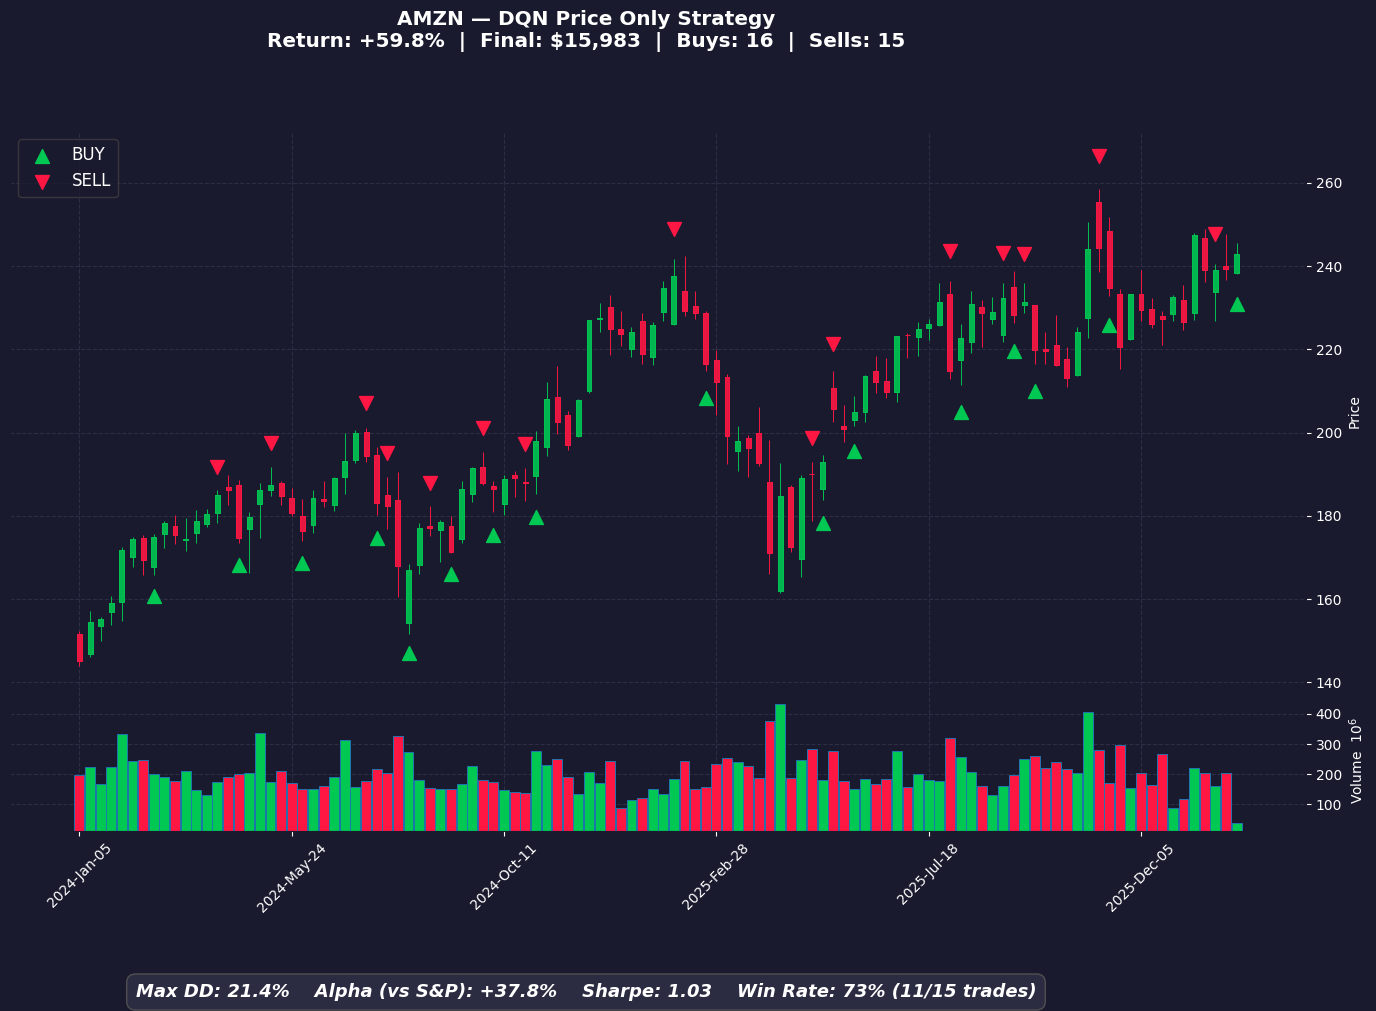

### AMZN — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_38119/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-26,BUY,$174.73,57,"$9,959.61","$9,990.04"
2024-04-08,SELL,$185.19,57,"$10,555.83","$10,575.70"
2024-04-22,BUY,$177.23,59,"$10,456.57","$10,565.25"
2024-05-13,SELL,$186.57,59,"$11,007.63","$11,105.30"
2024-05-28,BUY,$182.15,60,"$10,929.00","$11,094.37"
2024-07-15,SELL,$192.72,60,"$11,563.20","$11,717.01"
2024-07-22,BUY,$182.55,64,"$11,683.20","$11,705.32"
2024-07-29,SELL,$183.20,64,"$11,724.80","$11,735.20"
2024-08-12,BUY,$166.80,70,"$11,676.00","$11,723.52"
2024-08-26,SELL,$175.50,70,"$12,285.00","$12,320.24"


In [9]:
plot_ticker('AMZN', method='DQN_Price_Only')


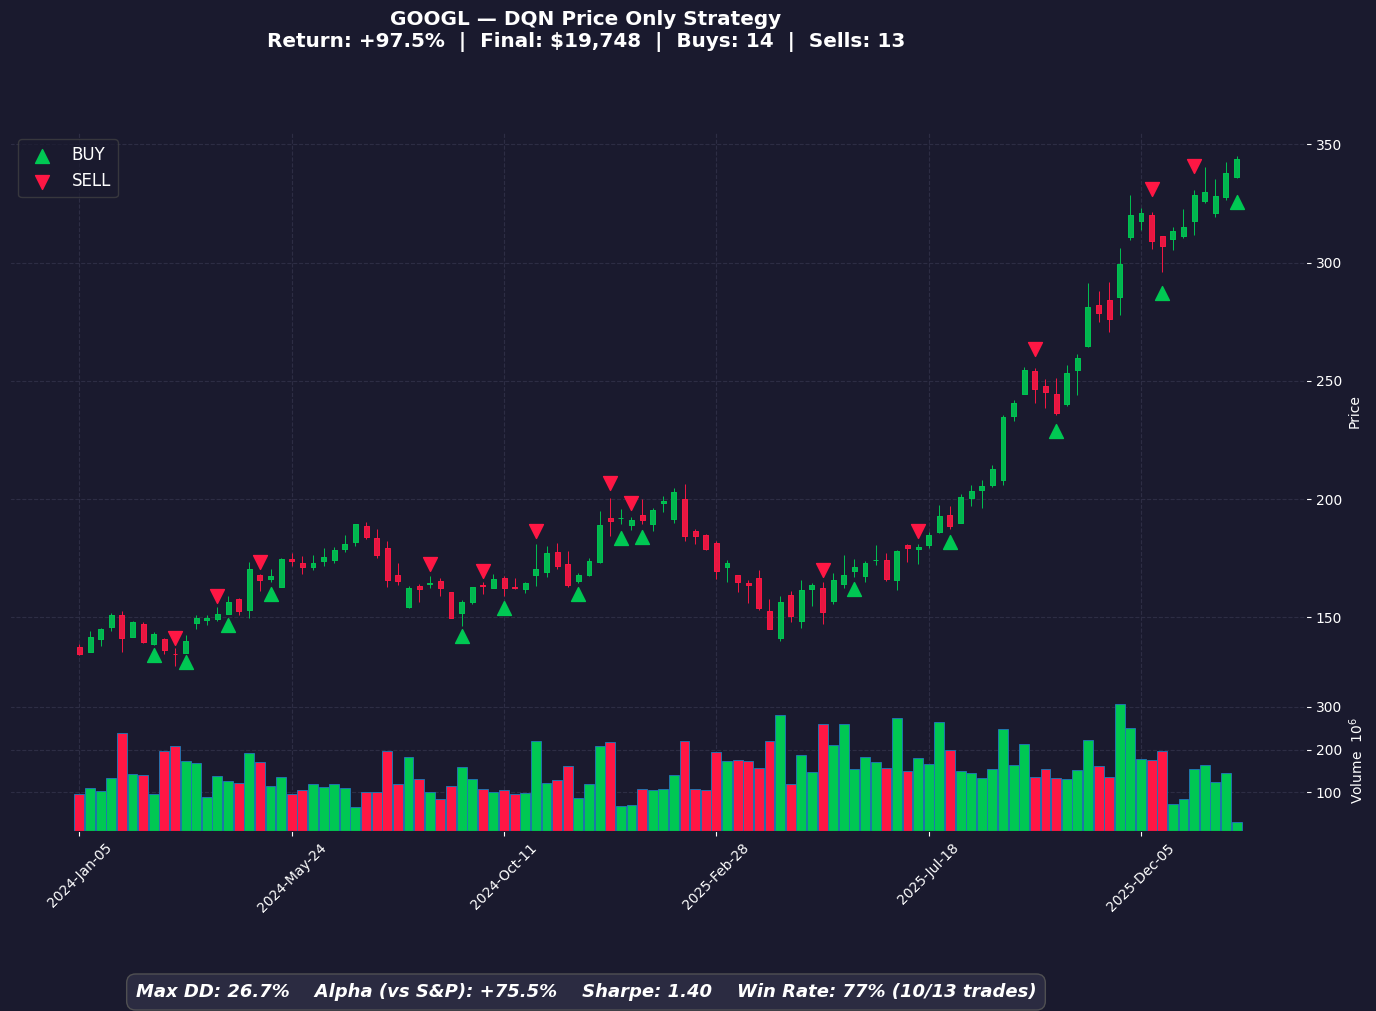

### GOOGL — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_38119/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$140.05,71,"$9,943.77","$9,990.06"
2024-03-11,SELL,$136.63,71,"$9,700.67","$9,737.26"
2024-03-18,BUY,$146.56,66,"$9,673.19","$9,727.58"
2024-04-08,SELL,$153.68,66,"$10,142.83","$10,187.08"
2024-04-15,BUY,$153.69,66,"$10,143.49","$10,176.94"
2024-05-06,SELL,$166.83,66,"$11,010.72","$11,033.16"
2024-05-13,BUY,$167.86,65,"$10,910.98","$11,022.25"
2024-08-26,SELL,$165.09,65,"$10,731.00","$10,831.53"
2024-09-16,BUY,$157.26,68,"$10,693.38","$10,820.84"
2024-09-30,SELL,$165.01,68,"$11,220.40","$11,336.65"


In [10]:
plot_ticker('GOOGL', method='DQN_Price_Only')


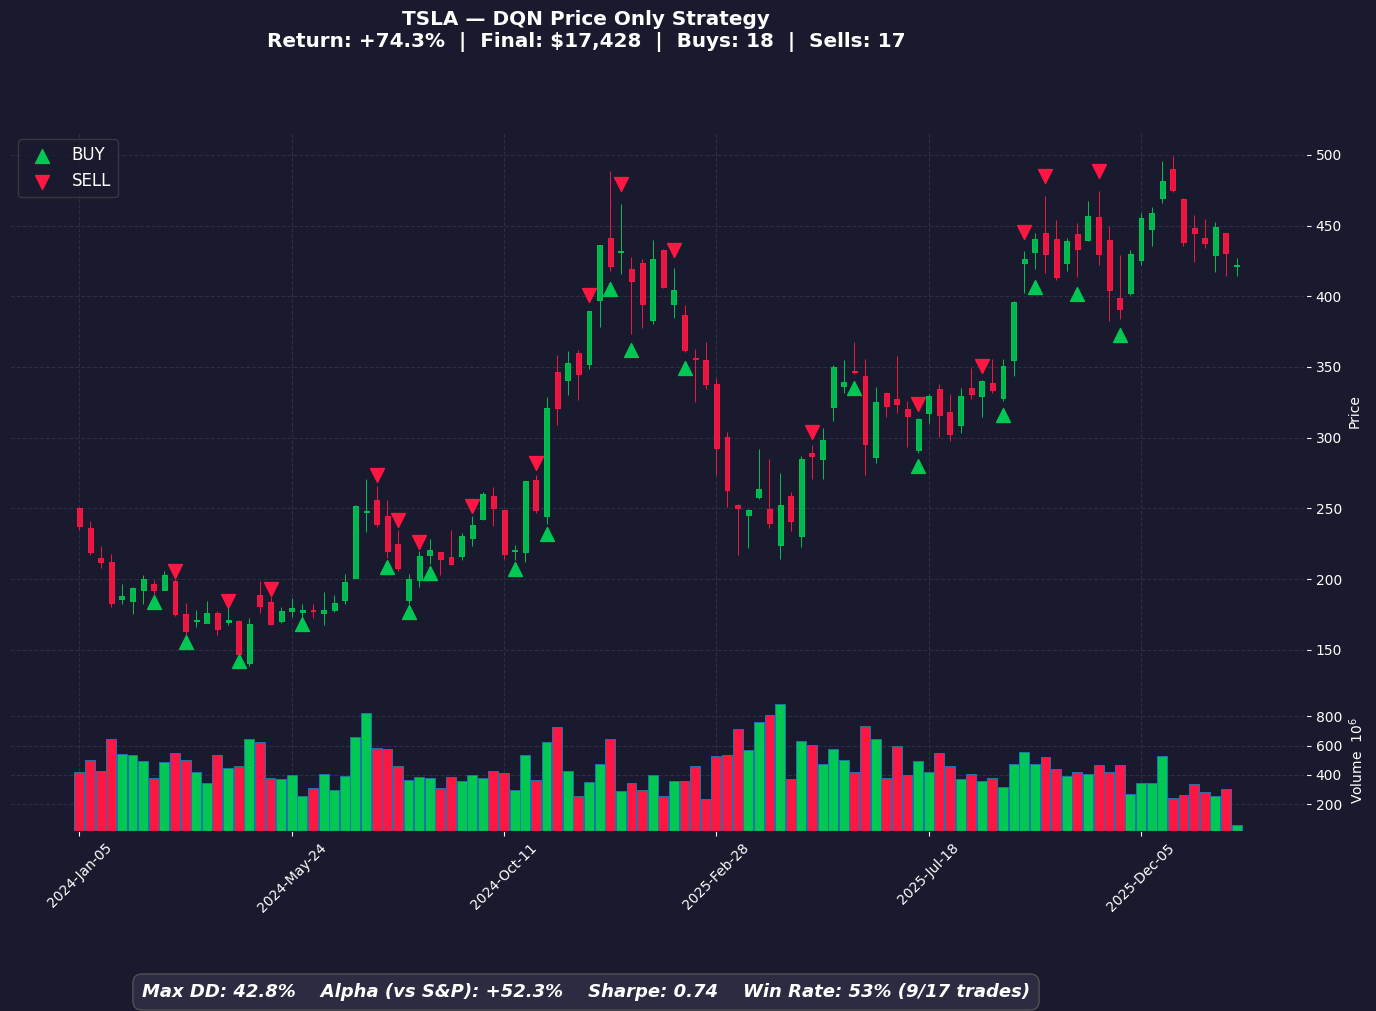

### TSLA — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_38119/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-26,BUY,$199.40,50,"$9,970.00","$9,990.03"
2024-03-11,SELL,$177.77,50,"$8,888.50","$8,899.64"
2024-03-18,BUY,$173.80,51,"$8,863.80","$8,890.78"
2024-04-15,SELL,$161.48,51,"$8,235.48","$8,254.22"
2024-04-22,BUY,$142.05,58,"$8,238.90","$8,245.98"
2024-05-13,SELL,$171.89,58,"$9,969.62","$9,966.73"
2024-06-03,BUY,$176.29,56,"$9,872.24","$9,956.86"
2024-07-22,SELL,$251.51,56,"$14,084.56","$14,155.10"
2024-07-29,BUY,$232.10,60,"$13,926.00","$14,141.17"
2024-08-05,SELL,$198.88,60,"$11,932.80","$12,136.04"


In [11]:
plot_ticker('TSLA', method='DQN_Price_Only')

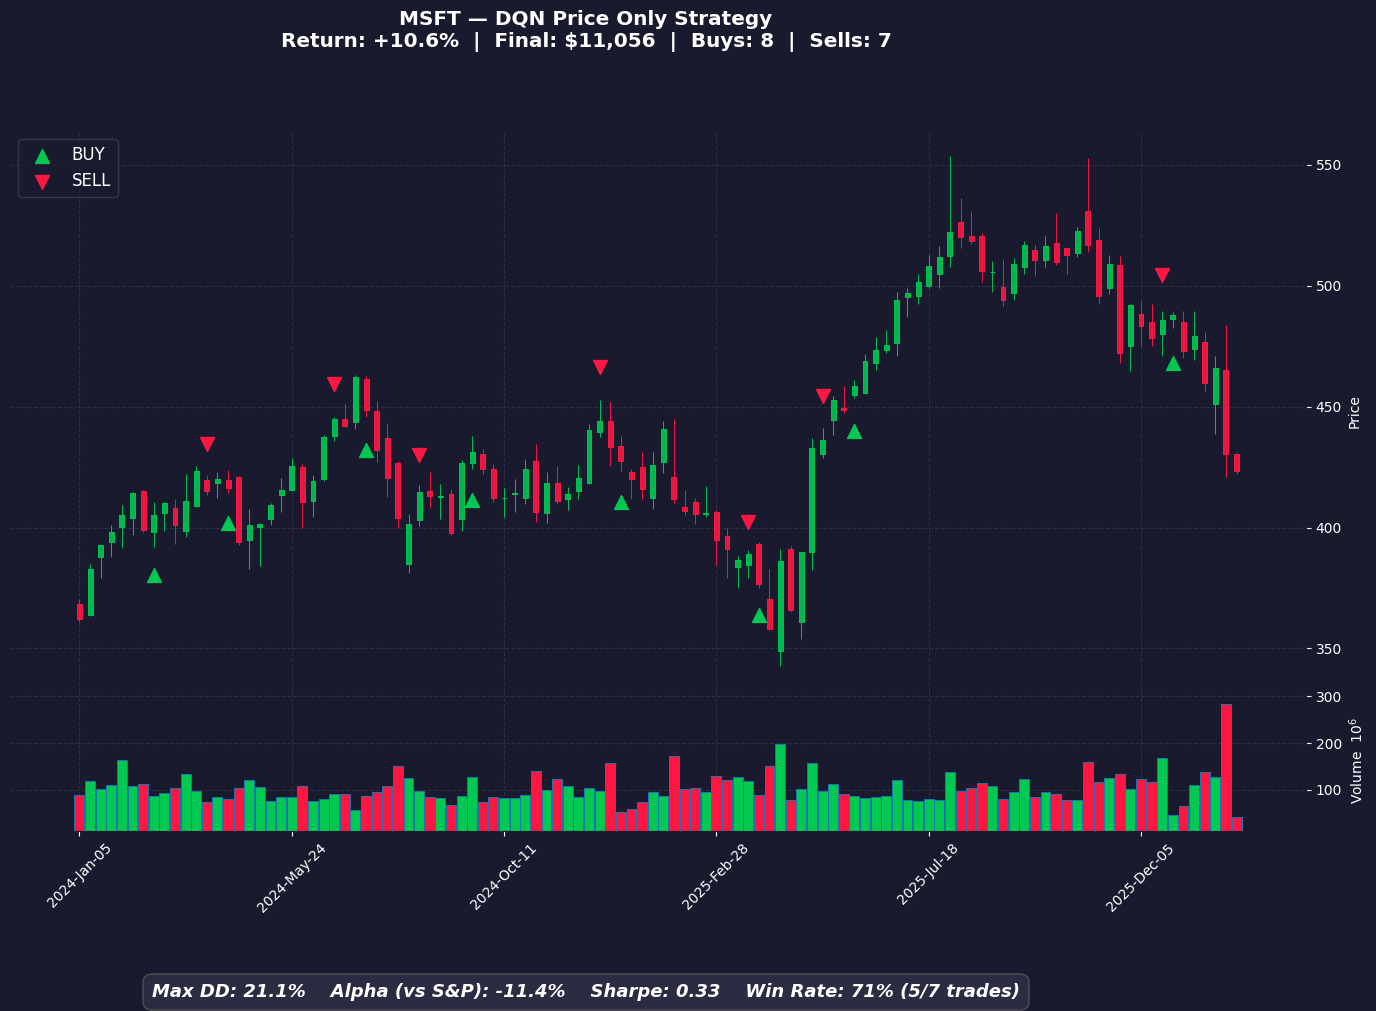

### MSFT — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_38119/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$397.62,25,"$9,940.42","$9,990.06"
2024-03-25,SELL,$417.43,25,"$10,435.72","$10,474.93"
2024-04-15,BUY,$408.33,25,"$10,208.18","$10,464.72"
2024-06-24,SELL,$442.70,25,"$11,067.59","$11,313.06"
2024-07-15,BUY,$448.92,25,"$11,223.10","$11,301.84"
2024-08-19,SELL,$417.60,25,"$10,439.91","$10,508.21"
2024-09-23,BUY,$429.46,24,"$10,307.15","$10,497.90"
2024-12-16,SELL,$448.28,24,"$10,758.60","$10,938.60"
2024-12-30,BUY,$421.71,25,"$10,542.79","$10,928.05"
2025-03-24,SELL,$390.97,25,"$9,774.32","$10,149.81"


In [12]:
plot_ticker('MSFT', method='DQN_Price_Only')

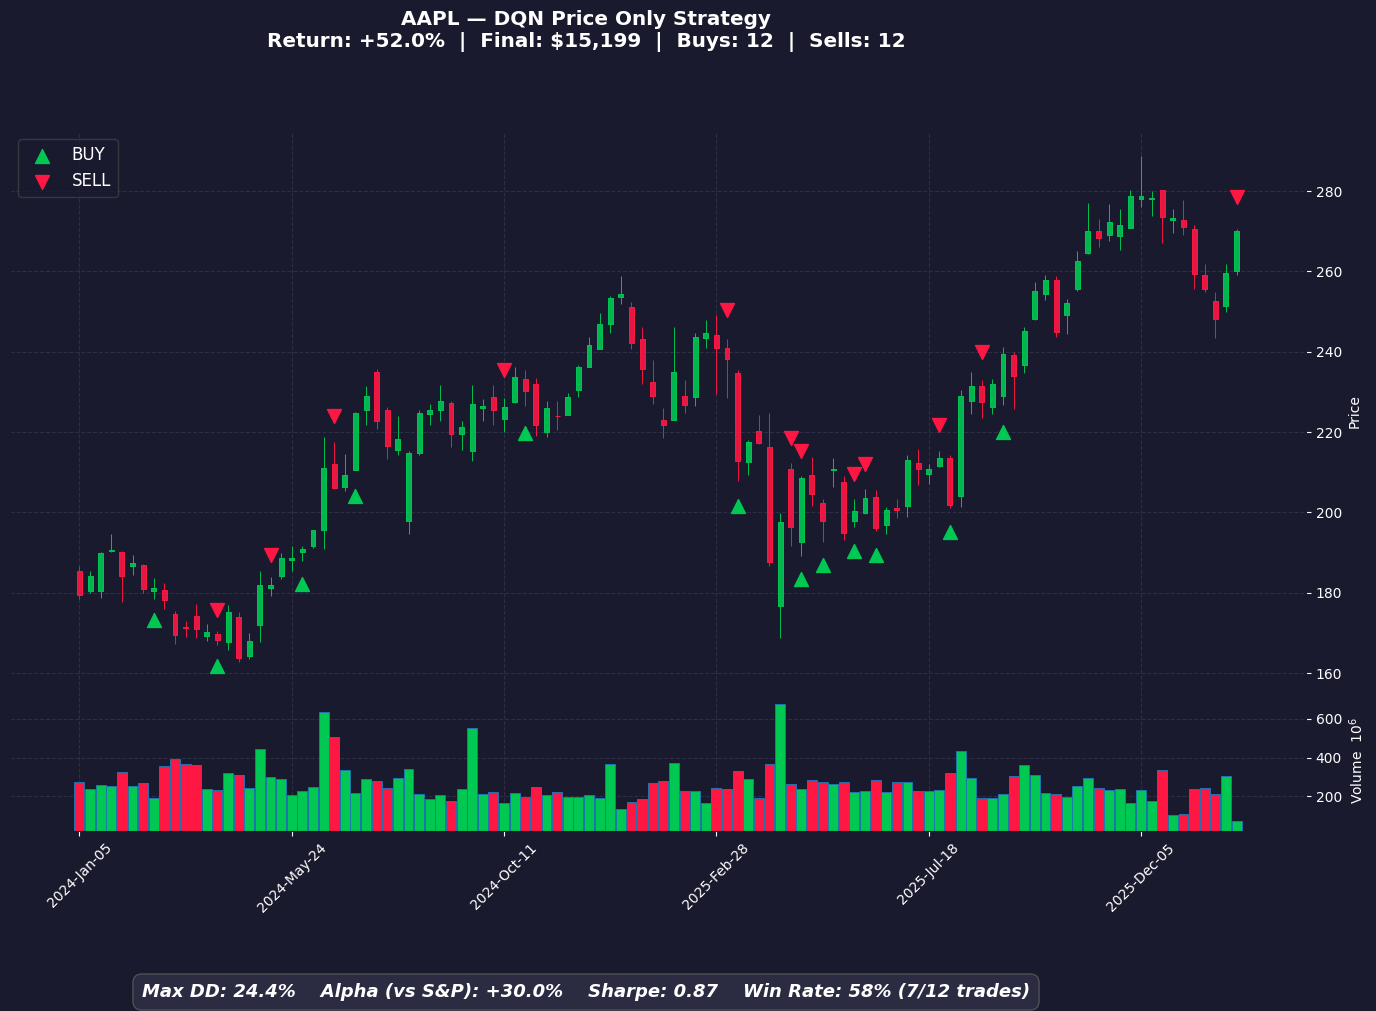

### AAPL — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_38119/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$180.10,55,"$9,905.71","$9,990.09"
2024-04-01,SELL,$168.67,55,"$9,276.64","$9,351.75"
2024-04-08,BUY,$167.10,55,"$9,190.44","$9,342.56"
2024-05-13,SELL,$185.04,55,"$10,177.11","$10,319.05"
2024-05-28,BUY,$188.72,54,"$10,191.07","$10,308.86"
2024-06-24,SELL,$206.75,54,"$11,164.64","$11,271.26"
2024-07-08,BUY,$226.30,49,"$11,088.77","$11,260.17"
2024-10-14,SELL,$230.02,49,"$11,271.09","$11,431.22"
2024-10-28,BUY,$232.11,49,"$11,373.42","$11,419.85"
2025-03-10,SELL,$226.72,49,"$11,109.34","$11,144.66"


In [13]:
plot_ticker('AAPL', method='DQN_Price_Only')

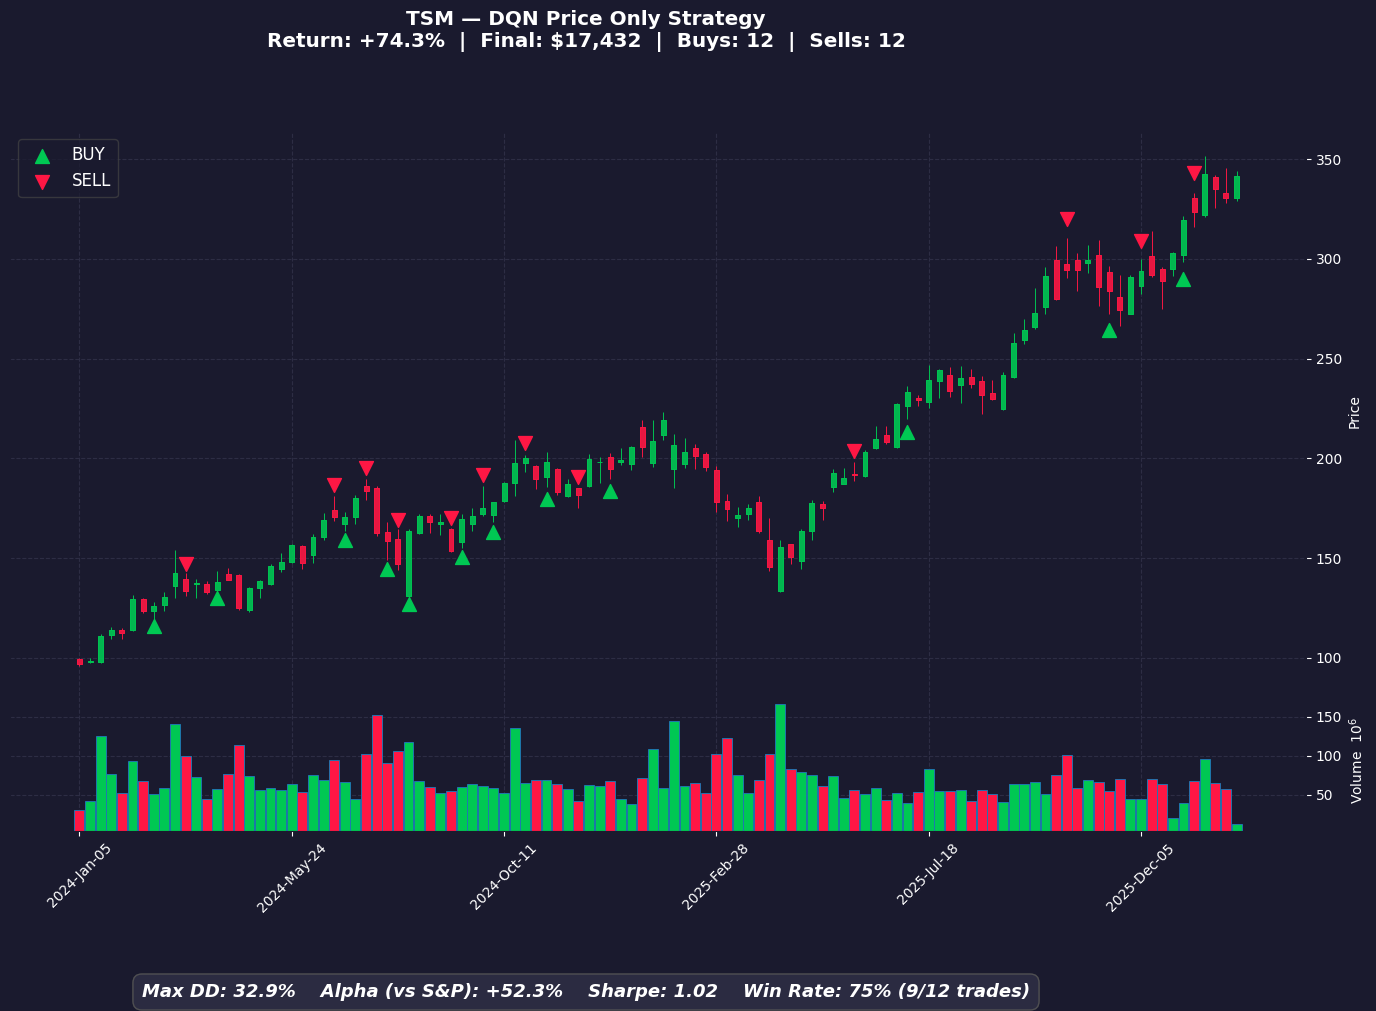

### TSM — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_38119/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-26,BUY,$127.14,78,"$9,916.62","$9,990.08"
2024-03-18,SELL,$133.51,78,"$10,414.08","$10,477.14"
2024-04-01,BUY,$138.25,75,"$10,368.97","$10,466.77"
2024-06-24,SELL,$164.49,75,"$12,336.52","$12,421.98"
2024-07-01,BUY,$168.92,73,"$12,330.97","$12,409.65"
2024-07-15,SELL,$181.55,73,"$13,253.31","$13,318.73"
2024-07-29,BUY,$156.84,84,"$13,174.68","$13,305.56"
2024-08-05,SELL,$145.02,84,"$12,181.70","$12,300.40"
2024-08-12,BUY,$164.31,74,"$12,158.98","$12,288.24"
2024-09-09,SELL,$159.56,74,"$11,807.18","$11,924.64"


In [14]:
plot_ticker('TSM', method='DQN_Price_Only')

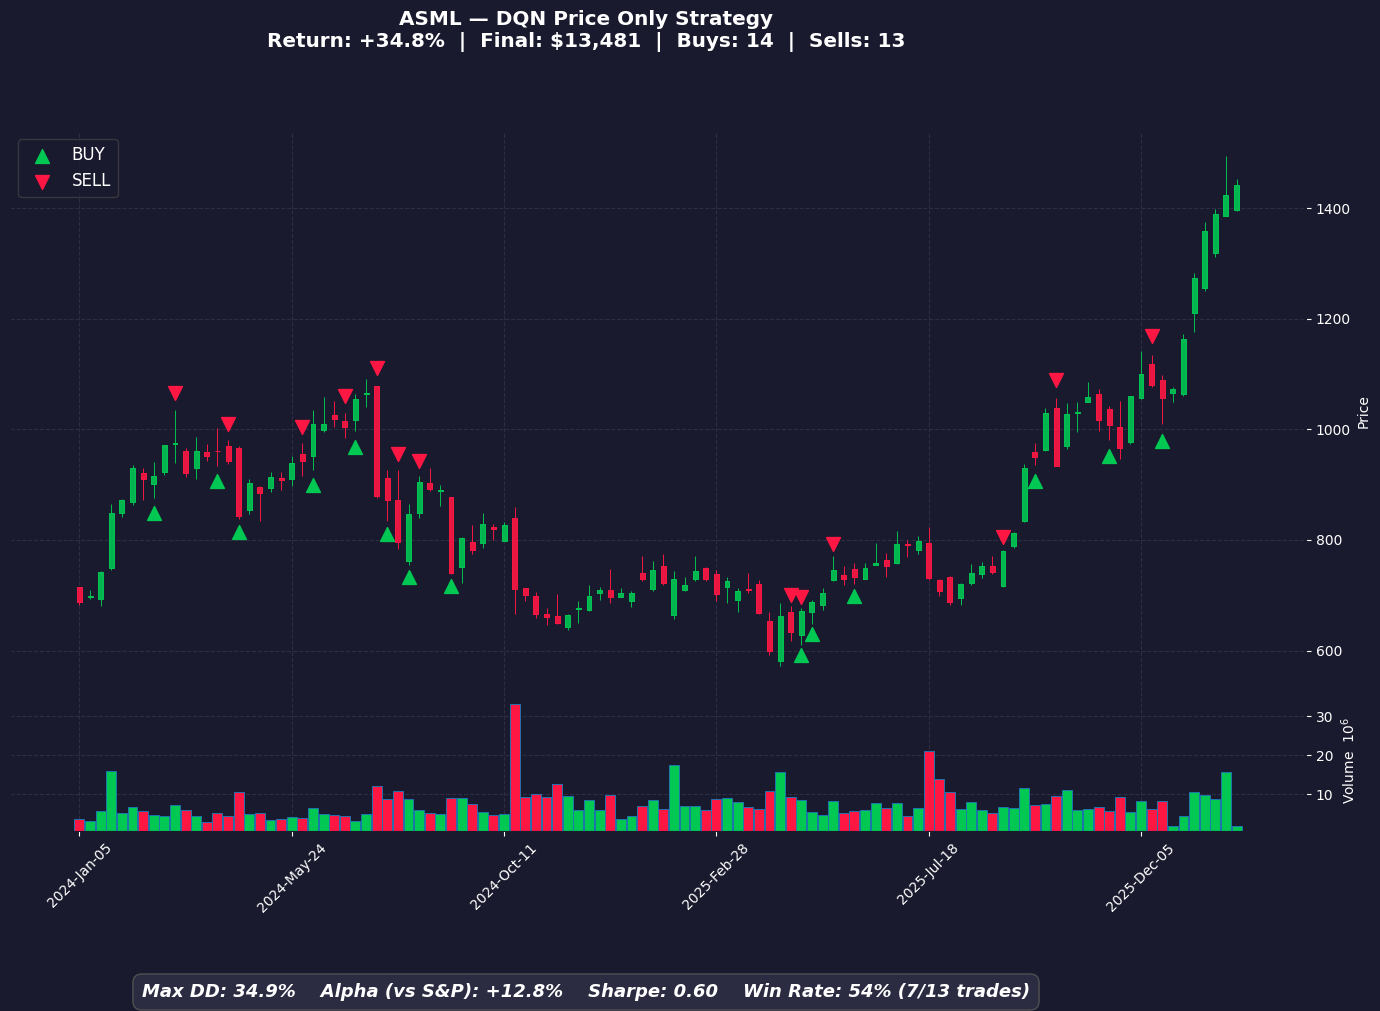

### ASML — Trade Log (DQN Price Only)

/var/folders/pz/_0kh2t797553_kjgmmh7_0fc0000gn/T/ipykernel_38119/3521736162.py:106: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled = log.style.applymap(


Date,Action,Price,Shares,Value,Portfolio
2024-02-20,BUY,$891.62,11,"$9,807.79","$9,990.19"
2024-03-11,SELL,$943.67,11,"$10,380.36","$10,552.38"
2024-04-01,BUY,$973.35,10,"$9,733.51","$10,542.65"
2024-04-15,SELL,$935.97,10,"$9,359.74","$10,159.52"
2024-04-22,BUY,$854.84,11,"$9,403.21","$10,150.11"
2024-06-03,SELL,$948.35,11,"$10,431.88","$11,168.35"
2024-06-10,BUY,"$1,023.23",10,"$10,232.30","$11,158.11"
2024-07-01,SELL,"$1,015.16",10,"$10,151.56","$11,067.22"
2024-07-08,BUY,"$1,058.28",10,"$10,582.77","$11,056.64"
2024-07-22,SELL,$924.56,10,"$9,245.62","$9,710.24"


In [15]:
plot_ticker('ASML', method='DQN_Price_Only')